<a href="https://colab.research.google.com/github/delaneydow/ncl_diffusion/blob/main/01_data_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RSNA data: download a subset, preprocess, cache, split
Turns RSNA ICH DICOMs into a small uint8 array cache on Drive (images.npy + manifest.csv), with patient-level train/val/test splits. Everything downstream (diffusion, GAN, classifier) reads this cache.

Before the first run

On kaggle.com, open the RSNA competition page and click Join / accept rules (downloads fail otherwise).
In Colab (key icon in the left bar) add secrets KAGGLE_USERNAME and KAGGLE_KEY, and turn on notebook access. If Kaggle has changed how API tokens work, follow their current instructions and keep the same two secret names.
Workflow: run with SMOKE = True first (400 images, a few minutes) to check everything, then set SMOKE = False. The config is saved at the end, so notebooks 02 and 03 automatically point at whichever cache you built last.


In [ ]:
# ====== BOOTSTRAP (identical in every notebook) ======
# Mounts Drive, links the project folder, installs anything missing, puts the package on sys.path.
import os, sys, json, importlib.util, importlib.metadata, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules

PROJECT = "/content/drive/MyDrive/ncl_diffusion" if IN_COLAB else os.path.abspath("ct_diffusion_project")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(PROJECT, exist_ok=True)
LINK = "/content/ncl_diffusion_project" if IN_COLAB else PROJECT   # short path used everywhere below
if LINK != PROJECT and not os.path.exists(LINK):
    os.symlink(PROJECT, LINK)

# pip name -> import name.
# NOTE: no `monai-generative` any more. MONAI >= 1.4 ships the diffusion code in core.
_pip = {"einops": "einops", "pydicom": "pydicom", "kaggle": "kaggle", "scikit-learn": "sklearn", "tqdm": "tqdm",
        "opencv-python-headless": "cv2", "pandas": "pandas", "matplotlib": "matplotlib",
        "torchmetrics": "torchmetrics", "torch-fidelity": "torch_fidelity"}
_missing = [p for p, m in _pip.items() if importlib.util.find_spec(m) is None]
try:
    from packaging.version import Version
    _monai_ok = Version(importlib.metadata.version("monai")) >= Version("1.4")
except Exception:          # not installed, or version string we can't parse
    _monai_ok = False
if not _monai_ok:
    _missing.append("monai>=1.4")
if _missing:
    print("installing:", _missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
if LINK not in sys.path:
    sys.path.insert(0, LINK)
print("project:", PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project: /content/drive/MyDrive/ncl_diffusion


In [ ]:
import sys
# === get RSNA imports; configurations ====
from IPython.display import display
import numpy as np, pandas as pd, shutil, time, torch
import matplotlib.pyplot as plt

# Ensure LINK is in sys.path for local package discovery
if LINK not in sys.path:
    sys.path.insert(0, LINK)

from ncl_diffusion.config import Config
from ncl_diffusion import data            # registers the RSNA adapter
from ncl_diffusion.registry import DATASETS
from ncl_diffusion.data import build_cache, load_cache, stratified_subset, make_splits, split_summary
from ncl_diffusion.utils import show_grid

cfg_path = Path(LINK) / "config.json"
cfg = Config.load(cfg_path) if cfg_path.exists() else Config()
cfg.paths.project = LINK

SMOKE = False            # True: tiny 400-image subset to test the plumbing.  False: the full subset below.
FORCE_REBUILD = True   # True: ignore an existing cache and rebuild from the DICOMs

cfg = cfg.override({
    "data.n_images": 400 if SMOKE else 15000,
    "data.img_size": 128,          # 128 is fast; small bleeds lose detail, so try 256 later
    "data.windows": [[40, 80]],    # 1 channel = brain window. Alternative: [[40,80],[80,200],[600,2800]] = brain/subdural/bone
    "data.pos_fraction": 0.15,     # share of the subset with any hemorrhage (natural rate is lower; None = natural rate)
})
print(cfg.save())
print("cache will live in:", cfg.cache_dir())

/content/ncl_diffusion_project/config.json
cache will live in: /content/ncl_diffusion_project/cache/rsna_ich_128px_n15000_w1


In [ ]:
# Kaggle auth check (reads Colab secrets)
from ncl_diffusion.data.rsna import kaggle_login
kaggle_login()
print("Kaggle login OK")

Kaggle login OK


In [ ]:
# Kaggle auth: reads Colab secrets, supports new-style tokens AND legacy username/key
import os, sys, json, subprocess
from pathlib import Path

# older kaggle versions don't understand the new tokens
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)

def _secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None   # missing secret, or Notebook access toggle is off

token = _secret("KAGGLE_API_TOKEN")
user  = _secret("KAGGLE_USERNAME")
key   = _secret("KAGGLE_KEY")

# a new-style token pasted into the KEY secret still works
if not token and key and key.startswith("KGAT_"):
    token, key = key, None

if token:
    os.environ["KAGGLE_API_TOKEN"] = token
    mode = "new-style token (KAGGLE_API_TOKEN)"
elif user and key:
    os.environ["KAGGLE_USERNAME"] = user
    os.environ["KAGGLE_KEY"] = key
    # also write kaggle.json for tools that only look for the file
    kdir = Path.home() / ".kaggle"
    kdir.mkdir(exist_ok=True)
    kjson = kdir / "kaggle.json"
    kjson.write_text(json.dumps({"username": user, "key": key}))
    kjson.chmod(0o600)
    mode = "legacy username + key"
else:
    raise RuntimeError(
        "No Kaggle credentials found. In the Colab key icon, add a secret named "
        "KAGGLE_API_TOKEN (or KAGGLE_USERNAME + KAGGLE_KEY) and switch ON 'Notebook access'."
    )

print("Kaggle credentials loaded via:", mode)

Kaggle credentials loaded via: new-style token (KAGGLE_API_TOKEN)


In [ ]:
# ============================================================
# Download RSNA Intracranial Hemorrhage Detection data
# ============================================================

import os
from pathlib import Path

DOWNLOAD_DIR = Path("/content/rsna_data")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Make sure Kaggle credentials are available
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Download the competition data
!kaggle competitions download \
    -c rsna-intracranial-hemorrhage-detection \
    -p /content/rsna_data

print("\nDownloaded files:")
!ls -lh /content/rsna_data

100% 181G/181G [1:57:12<00:00, 27.7MB/s]


Downloaded files:
total 182G
-rw-r--r-- 1 root root 182G May 16  2020 rsna-intracranial-hemorrhage-detection.zip


In [ ]:
ZIP_PATH    = Path("/content/rsna_data/rsna-intracranial-hemorrhage-detection.zip")   # the competition zip you downloaded
RAW_LOCAL   = Path("/content/rsna_raw")        # extracted DICOMs (local disk, deleted at the end)
LOCAL_BUILD = Path("/content/cache_local")     # caches are built here, then copied to Drive
LABELS_DIR  = Path(LINK) / "rsna_labels"       # small, persistent copy of the label CSV on Drive

BUILD_SKULLSTRIPPED = True    # also build the skull-stripped variant (same slices, same splits)
CLEAN_RAW_AFTER     = True    # delete extracted DICOMs + local build dirs at the end (after verification)
DELETE_ZIP_AFTER    = False   # also delete the big zip. Only do this once you are done building subsets.

# Skull-stripping heuristics (pixel/HU values, tune after looking at the comparison grid)
BONE_HU          = 300        # pixels above this count as skull
SOFT_LO, SOFT_HI = -20, 200   # tissue range kept inside the skull (keeps CSF, brain, and blood)
BRAIN_FRAC_RANGE = (0.04, 0.50)   # slices whose brain mask covers a fraction outside this are flagged strip_ok=False

import zipfile
from tqdm.auto import tqdm

def disk_report(tag=""):
    t = shutil.disk_usage("/content")
    print(f"[{tag}] local disk: {t.free / 1e9:.0f} GB free of {t.total / 1e9:.0f} GB")
disk_report("start")

[start] local disk: 17 GB free of 242 GB


# 1. Manifest and subset building

download the label CSV and pivot it to one row/slice w/ 6 label columns subset then draws the subset that will actually be downloaded.

In [ ]:
# --- helpers: random access into the Kaggle zip ---
_zip = {"z": None, "dcm": None}

def _open_zip():
    if _zip["z"] is None:
        assert ZIP_PATH.exists(), f"zip not found at {ZIP_PATH}. Download it again or fix ZIP_PATH."
        z = zipfile.ZipFile(ZIP_PATH)
        infos = z.infolist()
        dcm = {Path(i.filename).stem: i for i in infos
               if i.filename.endswith(".dcm") and f"{adapter.train_dir}/" in i.filename}
        if not dcm:      # tell the user what is actually in there instead of failing silently
            tops = sorted({i.filename.split("/")[0] for i in infos})[:15]
            nested = [i.filename for i in infos if i.filename.endswith(".zip")][:5]
            raise RuntimeError(f"No .dcm files under '{adapter.train_dir}/' in the zip.\n"
                               f"Top-level entries: {tops}\nNested zips: {nested}\n"
                               f"If the DICOMs are inside a nested zip, tell me and we'll unpack that first.")
        _zip["z"], _zip["dcm"] = z, dcm
        print(f"zip index: {len(dcm):,} DICOMs found under {adapter.train_dir}/")
    return _zip["z"], _zip["dcm"]

def get_label_csv():
    csv = Path(adapter.raw) / "stage_2_train.csv"
    keep_copy = LABELS_DIR / "stage_2_train.csv"
    if csv.exists():
        return csv
    csv.parent.mkdir(parents=True, exist_ok=True)
    if keep_copy.exists():
        shutil.copy(keep_copy, csv)
    else:
        z = zipfile.ZipFile(ZIP_PATH)
        name = next(i.filename for i in z.infolist() if i.filename.endswith("stage_2_train.csv"))
        with z.open(name) as src, open(csv, "wb") as dst:
            shutil.copyfileobj(src, dst)
        LABELS_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(csv, keep_copy)
    return csv

def ensure_dicoms(sample_ids):
    """Extract any missing DICOMs for these ids into adapter.raw/train_dir. Returns ids that are not in the zip."""
    out = Path(adapter.raw) / adapter.train_dir
    out.mkdir(parents=True, exist_ok=True)
    todo = [s for s in sample_ids if not (out / f"{s}.dcm").exists()]
    missing = []
    if todo:
        z, idx = _open_zip()
        for s in tqdm(todo, desc="extracting DICOMs"):
            info = idx.get(s)
            if info is None:
                missing.append(s); continue
            with z.open(info) as src, open(out / f"{s}.dcm", "wb") as dst:
                shutil.copyfileobj(src, dst)
    return missing

In [ ]:
adapter = DATASETS.build(cfg.data.dataset, cfg)
print("original raw dir:", adapter.raw)

# `raw` is a read-only property, so subclass the adapter and override it to point at local disk
class _LocalRaw(type(adapter)):
    raw = property(lambda self: RAW_LOCAL)
adapter.__class__ = _LocalRaw

print("raw dir:", adapter.raw, "| train dir:", adapter.train_dir)
get_label_csv()                     # so build_manifest() finds the CSV and skips the Kaggle download

full = adapter.build_manifest()
print(f"{len(full):,} slices in the label file")
display(full[cfg.data.label_cols].mean().round(4).to_frame("prevalence (full dataset)"))

# Persist the full label manifest (small). Later notebooks can redraw subsets or merge an external mask dataset without the zip.
LABELS_DIR.mkdir(parents=True, exist_ok=True)
full.assign(source="rsna", has_mask=False).to_csv(LABELS_DIR / "rsna_full_manifest.csv", index=False)

sub = stratified_subset(full, cfg.data.n_images, cfg.data.strat_col, cfg.data.pos_fraction, cfg.data.seed)
display(sub[cfg.data.label_cols].mean().round(4).to_frame("prevalence (our subset)"))

original raw dir: /content/raw/rsna
raw dir: /content/rsna_raw | train dir: stage_2_train
752,803 slices in the label file


,prevalence (full dataset)
sub,
epidural,0.0042
intraparenchymal,0.0480
intraventricular,0.0348
subarachnoid,0.0474
subdural,0.0627
any,0.1434


,prevalence (our subset)
sub,
epidural,0.0049
intraparenchymal,0.0527
intraventricular,0.0357
subarachnoid,0.0485
subdural,0.0653
any,0.1500


# Extract subset, pre-process, cache

In [ ]:
CACHE = cfg.cache_dir()
if (CACHE / "manifest.csv").exists() and not FORCE_REBUILD:
    print("Cache already on Drive, skipping build:", CACHE)

else:
    missing = ensure_dicoms(sub.sample_id)
    #if missing:
        #print(f"{len(missing)} slices not found in the zip, dropping them")
    sub = sub[~sub.sample_id.isin(missing)]
    disk_report("after extraction")

    LOCAL = LOCAL_BUILD / CACHE.name
    if LOCAL.exists():
        shutil.rmtree(LOCAL)
    man = build_cache(adapter, sub, LOCAL, workers=cfg.data.download_workers)   # DICOM -> HU -> window -> resize -> uint8
    man = make_splits(man, cfg.data.group_col, cfg.data.strat_col, tuple(cfg.data.split_fracs), cfg.data.seed)
    man["source"], man["has_mask"] = "rsna", False
    man.to_csv(LOCAL / "manifest.csv", index=False)

    CACHE.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(LOCAL, CACHE, dirs_exist_ok=True)
    #print("Saved cache to", CACHE)

images, man = load_cache(CACHE)
if "split" not in man.columns:      # cache built elsewhere without splits
    man = make_splits(man, cfg.data.group_col, cfg.data.strat_col, tuple(cfg.data.split_fracs), cfg.data.seed)
    man.to_csv(CACHE / "manifest.csv", index=False)
#print("images:", images.shape, images.dtype)

[after extraction] local disk: 17 GB free of 242 GB


preprocess:   0%|          | 0/15000 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'ID_b66acbcf83'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> for allowed values for each VR.
  warn_and_log(msg)
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'ID_568d5a982b'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> for allowed values for each VR.
  warn_and_log(msg)
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'ID_dd9366e62f'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> for allowed values for each VR.
  warn_and_log(msg)
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'ID_66c1b4e8f1'. Please see <https://dicom.nema.

# Derive skull-stripped variants

Same slices, same row order, same splits as the cache above. The only difference is that everything outside the brain is set to black before windowing and resizing.

Method (classical, no model): threshold the skull (> BONE_HU), close small gaps, fill the enclosed region, keep the tissue inside the bone ring (SOFT_LO..SOFT_HI HU, so blood stays in), and take the largest connected component. It works well on mid-brain slices and is least reliable near the skull base and the very top of the head, which is why every slice gets a strip_ok flag and a brain_frac value in the manifest.

In [ ]:
import cv2, pydicom
import scipy.ndimage as ndi
from concurrent.futures import ThreadPoolExecutor

_K_CLOSE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
_K3 = np.ones((3, 3), np.uint8)

def brain_mask(hu):
    closed = cv2.morphologyEx((hu > BONE_HU).astype(np.uint8), cv2.MORPH_CLOSE, _K_CLOSE)
    filled = ndi.binary_fill_holes(closed)
    interior = filled & ~cv2.dilate(closed, _K3, iterations=2).astype(bool)
    soft = (interior & (hu > SOFT_LO) & (hu < SOFT_HI)).astype(np.uint8)
    soft = cv2.morphologyEx(soft, cv2.MORPH_OPEN, _K3)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(soft, connectivity=4)
    if n <= 1:
        return np.zeros(hu.shape, bool)
    areas = stats[1:, cv2.CC_STAT_AREA]
    keep = 1 + np.flatnonzero(areas >= max(0.10 * areas.max(), 0.002 * hu.size))   # all pieces >= 10% of the largest
    return ndi.binary_fill_holes(np.isin(lab, keep))

def render(hu, windows, size, mask=None):
    """HU -> window(s) -> uint8 -> resize. Pixels outside `mask` become air (black)."""
    if mask is not None:
        hu = np.where(mask, hu, -1000.0)
    chans = []
    for c, w in windows:
        x = np.clip((hu - (c - w / 2)) / w, 0, 1)
        chans.append(cv2.resize((x * 255).round().astype(np.uint8), (size, size), interpolation=cv2.INTER_AREA))
    return np.stack(chans)

def _hu(sample_id):
    return adapter._to_hu(pydicom.dcmread(Path(adapter.raw) / adapter.train_dir / f"{sample_id}.dcm"))

def build_stripped(man, out_dir, workers=4):
    out_dir.mkdir(parents=True, exist_ok=True)
    S, W = cfg.data.img_size, cfg.data.windows
    pos = man.idx.to_numpy()
    assert sorted(pos) == list(range(len(man))), "manifest idx must be 0..N-1 so rows line up with images.npy"
    arr = np.lib.format.open_memmap(out_dir / "images.npy", mode="w+", dtype=np.uint8, shape=(len(man), len(W), S, S))
    frac = np.zeros(len(man), np.float32)
    ids = man.sample_id.tolist()
    def work(i):
        hu = _hu(ids[i]); m = brain_mask(hu)
        arr[pos[i]] = render(hu, W, S, m); frac[i] = m.mean()
    with ThreadPoolExecutor(workers) as ex:
        list(tqdm(ex.map(work, range(len(man))), total=len(man), desc="skull stripping"))
    arr.flush()
    out = man.copy()
    out["brain_frac"] = frac
    out["strip_ok"] = (frac > BRAIN_FRAC_RANGE[0]) & (frac < BRAIN_FRAC_RANGE[1])
    out["skull_stripped"] = True
    out.to_csv(out_dir / "manifest.csv", index=False)
    return out

CACHE_SS = CACHE.with_name(CACHE.name + "_skullstrip")
if not BUILD_SKULLSTRIPPED:
    print("skipping skull-stripped variant (BUILD_SKULLSTRIPPED = False)")
elif (CACHE_SS / "manifest.csv").exists() and not FORCE_REBUILD:
    print("Skull-stripped cache already on Drive, skipping build:", CACHE_SS)
else:
    missing = ensure_dicoms(man.sample_id)      # re-extracts if the DICOMs were cleaned up earlier
    assert not missing, f"{len(missing)} cached slices are missing from the zip"
    LOCAL_SS = LOCAL_BUILD / CACHE_SS.name
    if LOCAL_SS.exists():
        shutil.rmtree(LOCAL_SS)
    man_ss = build_stripped(man, LOCAL_SS, workers=cfg.data.download_workers)
    shutil.copytree(LOCAL_SS, CACHE_SS, dirs_exist_ok=True)
    print(f"Saved to {CACHE_SS} | strip_ok on {man_ss.strip_ok.mean():.1%} of slices")

skull stripping:   0%|          | 0/15000 [00:00<?, ?it/s]

Saved to /content/ncl_diffusion_project/cache/rsna_ich_128px_n15000_w1_skullstrip | strip_ok on 53.4% of slices


renderer vs adapter cache, mean abs diff (0-255 scale): 0.01  (want ~1 or less; if much larger the adapter windows/resizes differently and the two variants are not directly comparable)

strip_ok rate by any-hemorrhage label:


,strip_ok
any,
0,0.481
1,0.664


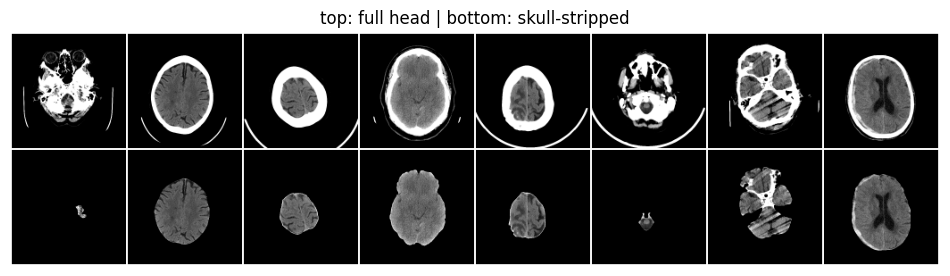

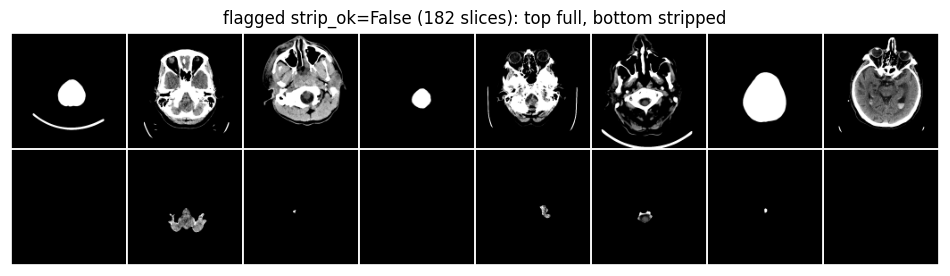

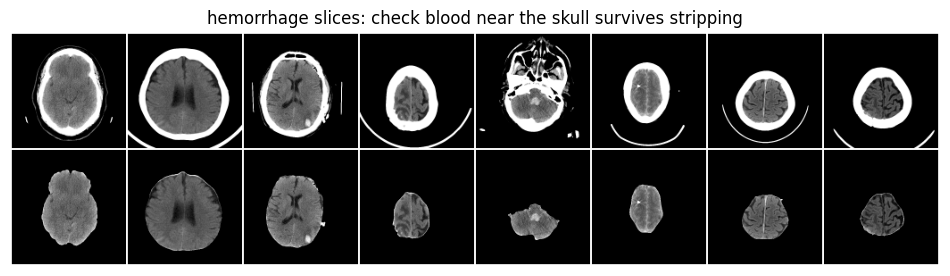

In [ ]:
# Compare variants: (1) check my renderer matches the adapter's cache (otherwise the comparison is not apples to apples),
# (2) look at the strip results, (3) see where stripping fails.
if BUILD_SKULLSTRIPPED:
    images_ss, man_ss = load_cache(CACHE_SS)

    chk = man.sample(min(20, len(man)), random_state=0)
    ensure_dicoms(chk.sample_id)
    diffs = [np.abs(render(_hu(r.sample_id), cfg.data.windows, cfg.data.img_size).astype(int) - images[r.idx].astype(int)).mean()
             for r in chk.itertuples()]
    print(f"renderer vs adapter cache, mean abs diff (0-255 scale): {np.mean(diffs):.2f}  "
          "(want ~1 or less; if much larger the adapter windows/resizes differently and the two variants are not directly comparable)")

    print("\nstrip_ok rate by any-hemorrhage label:")
    display(man_ss.groupby("any").strip_ok.mean().round(3).to_frame("strip_ok"))

    sel = man_ss.sample(8, random_state=1).idx.to_numpy()
    top = torch.from_numpy(images[sel]).float() / 255
    bot = torch.from_numpy(images_ss[sel]).float() / 255
    show_grid(torch.cat([top, bot]), nrow=8, title="top: full head | bottom: skull-stripped", figsize=(12, 3.4))

    bad = man_ss[~man_ss.strip_ok]
    if len(bad):
        b = bad.sample(min(8, len(bad)), random_state=0).idx.to_numpy()
        show_grid(torch.cat([torch.from_numpy(images[b]).float() / 255, torch.from_numpy(images_ss[b]).float() / 255]),
                  nrow=8, title=f"flagged strip_ok=False ({len(bad)} slices): top full, bottom stripped", figsize=(12, 3.4))

    pos_rows = man_ss[man_ss["any"] == 1]
    if len(pos_rows):
        p = pos_rows.sample(min(8, len(pos_rows)), random_state=2).idx.to_numpy()
        show_grid(torch.cat([torch.from_numpy(images[p]).float() / 255, torch.from_numpy(images_ss[p]).float() / 255]),
                  nrow=8, title="hemorrhage slices: check blood near the skull survives stripping", figsize=(12, 3.4))

too small (<0.04): 45.5% | too large (>0.5): 0.0%


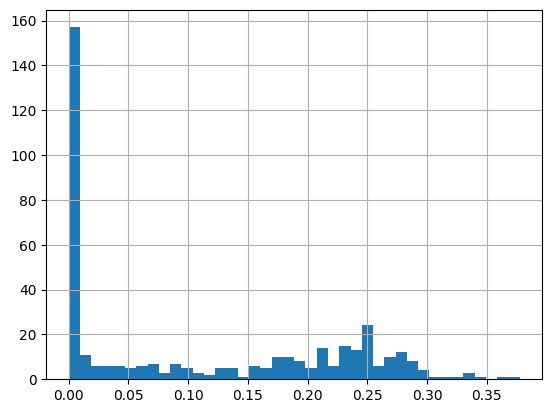

In [ ]:
lo, hi = BRAIN_FRAC_RANGE
print(f"too small (<{lo}): {(man_ss.brain_frac < lo).mean():.1%} | too large (>{hi}): {(man_ss.brain_frac > hi).mean():.1%}")
man_ss.brain_frac.hist(bins=40);

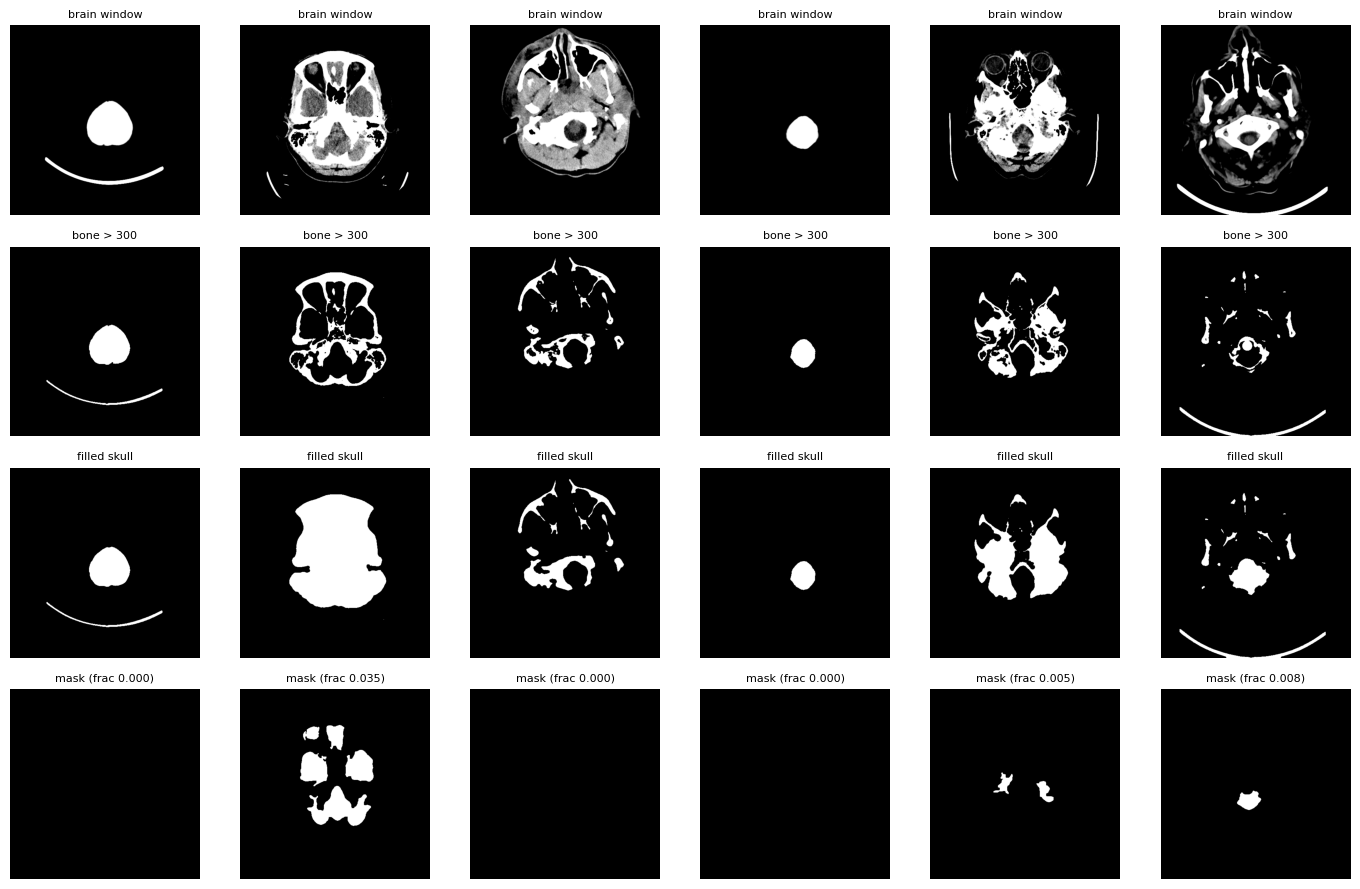

In [ ]:
# diagnose smoke set
bad = man_ss[man_ss.brain_frac < BRAIN_FRAC_RANGE[0]].sample(6, random_state=0)
ensure_dicoms(bad.sample_id)
fig, ax = plt.subplots(4, 6, figsize=(14, 9))
for j, r in enumerate(bad.itertuples()):
    hu = _hu(r.sample_id)
    bone = (hu > BONE_HU).astype(np.uint8)
    closed = cv2.morphologyEx(bone, cv2.MORPH_CLOSE, _K_CLOSE)
    filled = ndi.binary_fill_holes(closed)
    for i, (im, t) in enumerate([(np.clip(hu, 0, 80), "brain window"), (bone, f"bone > {BONE_HU}"),
                                 (filled, "filled skull"), (brain_mask(hu), f"mask (frac {r.brain_frac:.3f})")]):
        ax[i, j].imshow(im, cmap="gray"); ax[i, j].set_title(t, fontsize=8); ax[i, j].axis("off")
plt.tight_layout()

In [ ]:
for r in bad.itertuples():
    hu = _hu(r.sample_id)
    closed = cv2.morphologyEx((hu > BONE_HU).astype(np.uint8), cv2.MORPH_CLOSE, _K_CLOSE)
    filled = ndi.binary_fill_holes(closed)
    interior = filled & ~cv2.dilate(closed, _K3, iterations=2).astype(bool)
    in_range = interior & (hu > SOFT_LO) & (hu < SOFT_HI)
    opened = cv2.morphologyEx(in_range.astype(np.uint8), cv2.MORPH_OPEN, _K3)
    n, _, st, _ = cv2.connectedComponentsWithStats(opened, connectivity=4)
    big = st[1:, cv2.CC_STAT_AREA].max() / hu.size if n > 1 else 0
    head = hu[hu > np.percentile(hu, 60)]     # rough look at the non-air pixels
    p = np.percentile(hu[filled], [5, 50, 95]) if filled.any() else [np.nan] * 3
    print(f"{r.sample_id}: bone {closed.mean():.3f} | filled {filled.mean():.3f} | interior {interior.mean():.3f} | "
          f"in-range {in_range.mean():.3f} | opened {opened.mean():.3f} | largest {big:.3f} | "
          f"HU p5/p50/p95 inside filled: {p[0]:.0f}/{p[1]:.0f}/{p[2]:.0f}")

ID_faf67f239: bone 0.042 | filled 0.042 | interior 0.000 | in-range 0.000 | opened 0.000 | largest 0.000 | HU p5/p50/p95 inside filled: 315/536/869
ID_c59dfca21: bone 0.087 | filled 0.230 | interior 0.116 | in-range 0.092 | opened 0.091 | largest 0.035 | HU p5/p50/p95 inside filled: -268/60/1242
ID_f86e33a04: bone 0.052 | filled 0.055 | interior 0.001 | in-range 0.001 | opened 0.000 | largest 0.000 | HU p5/p50/p95 inside filled: 221/522/1182
ID_a1696b63a: bone 0.015 | filled 0.015 | interior 0.000 | in-range 0.000 | opened 0.000 | largest 0.000 | HU p5/p50/p95 inside filled: 330/578/832
ID_7273b8049: bone 0.086 | filled 0.110 | interior 0.015 | in-range 0.013 | opened 0.013 | largest 0.005 | HU p5/p50/p95 inside filled: 22/532/1450
ID_a97187adb: bone 0.036 | filled 0.047 | interior 0.009 | in-range 0.008 | opened 0.008 | largest 0.008 | HU p5/p50/p95 inside filled: 14/331/735


# Additional Sanity Checks
Split sizes and label balance, example slices, and how much of the HU range the window(s) cut off.

In [ ]:
display(split_summary(man, cfg.data.label_cols, cfg.data.group_col))
print("slices per patient in this subset:\n", man.groupby(cfg.data.group_col).size().describe().round(2).to_string())

,n_images,n_patients,prev_epidural,prev_intraparenchymal,prev_intraventricular,prev_subarachnoid,prev_subdural,prev_any
split,,,,,,,,
train,10481,6943,0.005,0.053,0.035,0.049,0.066,0.150
val,1503,993,0.005,0.050,0.042,0.047,0.073,0.156
test,3016,1985,0.004,0.052,0.036,0.049,0.060,0.148


slices per patient in this subset:
 count    9921.00
mean        1.51
std         0.88
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        12.00


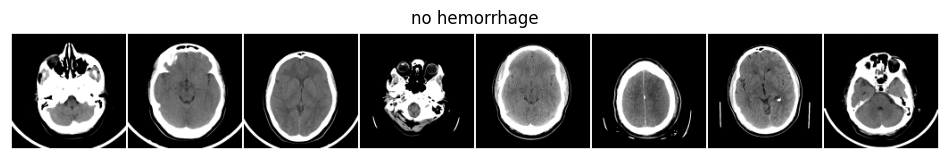

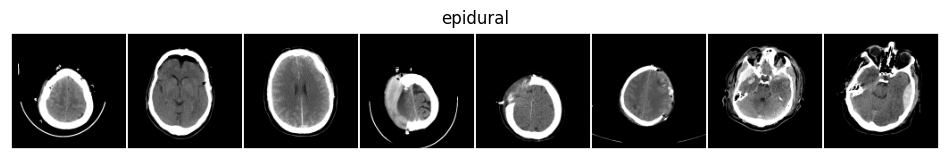

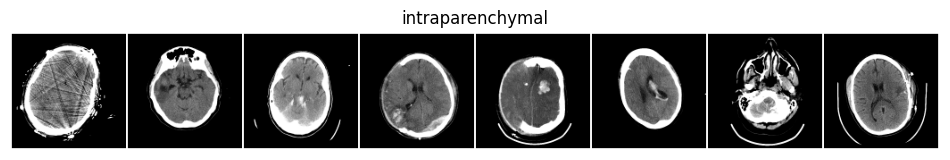

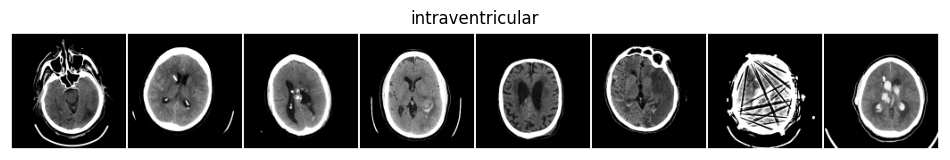

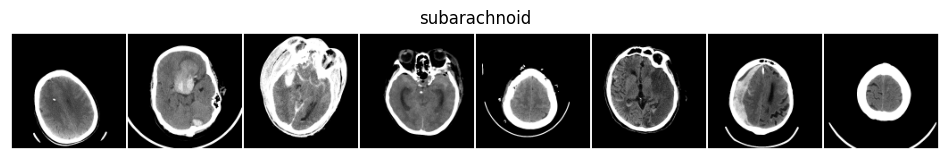

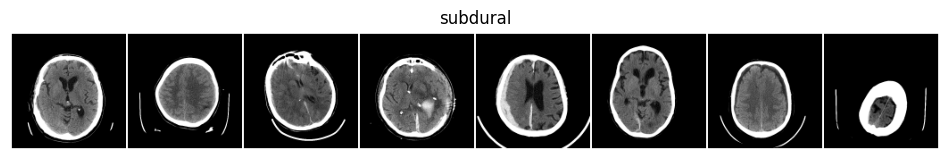

In [ ]:
# Example slices: negatives first, then each hemorrhage subtype
lc = cfg.data.label_cols
X = torch.from_numpy(images).float() / 255
groups = [("no hemorrhage", man[man["any"] == 0])] + [(c, man[man[c] == 1]) for c in lc if c != "any"]
for name, m in groups:
    if len(m):
        show_grid(X[m.sample(min(8, len(m)), random_state=0).idx.to_numpy()], nrow=8, title=name, figsize=(12, 2))

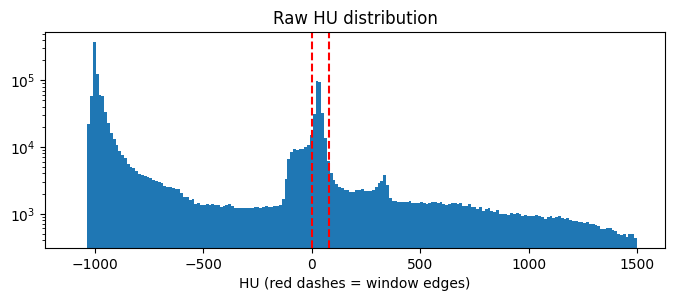

channel 0 window [40, 80]: 70.2% of pixels below the window (0), 6.8% above it (255)


In [ ]:
# Raw HU distribution (from a few DICOMs) with the window edges marked, plus how many cached pixels hit the window limits
import pydicom
rows = sub.sample(min(100, len(sub)), random_state=0)
hu = np.concatenate([adapter._to_hu(pydicom.dcmread(adapter.raw / adapter.train_dir / f"{s}.dcm")).ravel()[::16]
                     for s in rows.sample_id])
plt.figure(figsize=(8, 2.8))
plt.hist(hu, bins=200, range=(-1100, 1500), log=True)
for c, w in cfg.data.windows:
    plt.axvline(c - w / 2, color="r", ls="--"); plt.axvline(c + w / 2, color="r", ls="--")
plt.xlabel("HU (red dashes = window edges)"); plt.title("Raw HU distribution"); plt.show()

for c in range(images.shape[1]):
    v = images[:500, c].ravel()
    print(f"channel {c} window {cfg.data.windows[c]}: {np.mean(v == 0):.1%} of pixels below the window (0), "
          f"{np.mean(v == 255):.1%} above it (255)")

# Cleanup

Deletes the extracted DICOMs and local build folders, but only after both caches on Drive load and have the right shapes. The zip is only deleted if DELETE_ZIP_AFTER = True.

In [ ]:
def _verify(path):
    imgs, m = load_cache(path)
    return len(m) == imgs.shape[0] > 0 and int(imgs[:50].max()) > 0

caches = [CACHE] + ([CACHE_SS] if BUILD_SKULLSTRIPPED else [])
all_ok = all(_verify(p) for p in caches)
print("caches verified:", all_ok, [str(p) for p in caches])
disk_report("before cleanup")

if CLEAN_RAW_AFTER and all_ok:
    shutil.rmtree(RAW_LOCAL, ignore_errors=True)       # extracted DICOMs
    shutil.rmtree(LOCAL_BUILD, ignore_errors=True)     # local copies of the caches (Drive has them)
    print("deleted extracted DICOMs and local build dirs")
elif CLEAN_RAW_AFTER:
    print("NOT cleaning up: a cache failed verification. Fix that first.")

if DELETE_ZIP_AFTER and all_ok and ZIP_PATH.exists():
    ZIP_PATH.unlink()
    print("deleted", ZIP_PATH)
disk_report("after cleanup")

caches verified: True ['/content/ncl_diffusion_project/cache/rsna_ich_128px_n15000_w1', '/content/ncl_diffusion_project/cache/rsna_ich_128px_n15000_w1_skullstrip']
[before cleanup] local disk: 17 GB free of 242 GB
deleted extracted DICOMs and local build dirs
[after cleanup] local disk: 25 GB free of 242 GB


In [ ]:
import json
variants = {"full_head": str(CACHE)}
if BUILD_SKULLSTRIPPED:
    variants["skull_stripped"] = str(CACHE_SS)
(Path(LINK) / "cache_variants.json").write_text(json.dumps(variants, indent=2))
print("saved config:", cfg.save())
print("cache variants:", variants, "(also in cache_variants.json)")
print("Next: 02_train_diffusion.ipynb. For the healthy-brain baseline, train on rows with any == 0 in the split == 'train' part of whichever variant you pick.")

saved config: /content/ncl_diffusion_project/config.json
cache variants: {'full_head': '/content/ncl_diffusion_project/cache/rsna_ich_128px_n15000_w1', 'skull_stripped': '/content/ncl_diffusion_project/cache/rsna_ich_128px_n15000_w1_skullstrip'} (also in cache_variants.json)
Next: 02_train_diffusion.ipynb. For the healthy-brain baseline, train on rows with any == 0 in the split == 'train' part of whichever variant you pick.


In [ ]:
((man.any == 0) & man_ss.strip_ok).sum()

np.int64(0)